Experiment 3: Understand supervised learning to train and develop classifier models.

Software Used: Google colaboratory


In [7]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


**Code 1: Installation of Required Libraries**

In [8]:
!pip install -q pandas numpy matplotlib seaborn scikit-learn
# This code installs the essential Python libraries required for data analysis, visualization, and machine learning.

**Code 2: Importing Required Libraries**

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import matthews_corrcoef
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import roc_auc_score
from sklearn.metrics import cohen_kappa_score
from sklearn.metrics import roc_curve

# This code imports the necessary libraries and functions for data processing, visualization, model training, cross-validation, and performance evaluation.

**Code 3: Loading the Heart Disease Dataset**

In [11]:
df = pd.read_csv("/content/Student_performance_data _ (1).csv")

df.head()

# This code loads the heart disease dataset from a CSV file into a Pandas DataFrame named df.

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0


**Code 4: Checking Dataset Information**

In [12]:
df.info()
# This code displays basic information about the dataset, including the number of rows and columns, column names, data types, and missing values.


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2392 entries, 0 to 2391
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   StudentID          2392 non-null   int64  
 1   Age                2392 non-null   int64  
 2   Gender             2392 non-null   int64  
 3   Ethnicity          2392 non-null   int64  
 4   ParentalEducation  2392 non-null   int64  
 5   StudyTimeWeekly    2392 non-null   float64
 6   Absences           2392 non-null   int64  
 7   Tutoring           2392 non-null   int64  
 8   ParentalSupport    2392 non-null   int64  
 9   Extracurricular    2392 non-null   int64  
 10  Sports             2392 non-null   int64  
 11  Music              2392 non-null   int64  
 12  Volunteering       2392 non-null   int64  
 13  GPA                2392 non-null   float64
 14  GradeClass         2392 non-null   float64
dtypes: float64(3), int64(12)
memory usage: 280.4 KB


**Code 5: Displaying Statistical Summary of Dataset**

In [13]:
df.describe()
# This code provides descriptive statistics such as count, mean, standard deviation, minimum, maximum, and quartile values for numerical columns.

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
count,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000
mean,2196.500000,16.468645,0.510870,0.877508,1.746237,9.771992,14.541388,0.301421,2.122074,0.383361,0.303512,0.196906,0.157191,1.906186,2.983696
std,690.655244,1.123798,0.499986,1.028476,1.000411,5.652774,8.467417,0.458971,1.122813,0.486307,0.459870,0.397744,0.364057,0.915156,1.233908
min,1001.000000,15.000000,0.000000,0.000000,0.000000,0.001057,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1598.750000,15.000000,0.000000,0.000000,1.000000,5.043079,7.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.174803,2.000000
50%,2196.500000,16.000000,1.000000,0.000000,2.000000,9.705363,15.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,1.893393,4.000000
75%,2794.250000,17.000000,1.000000,2.000000,2.000000,14.408410,22.000000,1.000000,3.000000,1.000000,1.000000,0.000000,0.000000,2.622216,4.000000
max,3392.000000,18.000000,1.000000,3.000000,4.000000,19.978094,29.000000,1.000000,4.000000,1.000000,1.000000,1.000000,1.000000,4.000000,4.000000


**Code 6: Separating Features and Target Variable**

In [20]:
X = df.drop("", axis=1)
y = df["target"]

# This code separates the independent variables into X and the target variable into y. The target column represents the output that the machine learning model will predict.

**Code 7: Splitting Dataset into Training and Testing Data**

In [21]:
X_train, X_test, y_train, y_test = train_test_split(

    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
print("Original Dataset Shape:", X.shape)
print("Training Feature Shape:", X_train.shape)
print("Testing Feature Shape:", X_test.shape)
print()

print("Original Target Shape:", y.shape)
print("Training Target Shape:", y_train.shape)
print("Testing Target Shape: ", y_test.shape)

# This code divides the dataset into 80% training data and 20% testing data. Stratification maintains approximately the same class distribution in both sets.


Original Dataset Shape: (2392, 13)
Training Feature Shape: (1913, 13)
Testing Feature Shape: (479, 13)

Original Target Shape: (2392,)
Training Target Shape: (1913,)
Testing Target Shape:  (479,)


**Code 8: Feature Scaling Using StandardScaler**

In [22]:
#This code standardizes the numerical features so that they have approximately a mean of 0 and a standard deviation of 1.

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

**Code 9: Creating Gaussian Naive Bayes Model**

In [23]:
#This code creates an instance of the Gaussian Naive Bayes classifier, which will be used for classification.

model = GaussianNB()

**Code 10: Applying Stratified K-Fold Cross-Validation**

In [24]:
cv = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    model,
    X_train,
    y_train,
    cv=cv,
    scoring='accuracy'
)

print("Cross Validation Accuracy")
print(cv_scores)

print("Mean Accuracy :", cv_scores.mean())
print("Standard Deviation :", cv_scores.std())

Cross Validation Accuracy
[0.796875   0.79166667 0.77604167 0.78534031 0.7486911  0.72774869
 0.7591623  0.80104712 0.7434555  0.7591623 ]
Mean Accuracy : 0.7689190663176265
Standard Deviation : 0.02365278174265297


**Code 11: Training the Gaussian Naive Bayes Model**

In [25]:
#This code trains the Gaussian Naive Bayes model using the complete training dataset.

model.fit(X_train, y_train)

GaussianNB()

**Code 12: Predicting Test Data Output**

In [26]:

#This code predicts the class labels and probabilities for the unseen test data.y_pred = model.predict(X_test)
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]


**Code 13: Comparing Actual and Predicted Values**

In [27]:
#This code creates a DataFrame to compare the actual test values with the values predicted by the model.

comparison = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred
})

print(comparison)

      Actual  Predicted
1167     4.0        4.0
1839     4.0        4.0
2122     4.0        4.0
1460     4.0        4.0
352      2.0        2.0
...      ...        ...
204      4.0        4.0
1314     1.0        1.0
1964     4.0        3.0
1953     2.0        2.0
1414     4.0        4.0

[479 rows x 2 columns]


**Code 14: Displaying Prediction Probability and Correct Status**

In [ ]:
#This code displays the actual class, predicted class, prediction probability, and whether each prediction is correct or incorrect.

comparison = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred,
    "Probability": y_prob
})

comparison["Correct"] = comparison["Actual"] == comparison["Predicted"]

print(comparison.head(20))

      Actual  Predicted   Probability  Correct
756        0          0  2.742491e-05     True
353        1          0  8.463733e-03    False
929        0          0  3.873253e-05     True
129        1          1  7.265454e-01     True
591        0          0  3.788311e-02     True
633        0          0  1.347302e-05     True
314        1          1  9.358168e-01     True
717        0          0  4.620684e-02     True
31         1          1  9.982792e-01     True
887        1          0  8.463733e-03    False
638        0          1  9.344050e-01    False
286        1          1  9.733371e-01     True
405        0          0  4.620684e-02     True
467        0          0  8.401525e-03     True
192        1          1  9.524171e-01     True
89         0          0  6.251965e-05     True
93         0          0  1.802370e-03     True
1013       0          0  5.639056e-07     True
142        0          0  3.619742e-01     True
807        1          1  9.770888e-01     True


**Code 15: Generating Confusion Matrix**

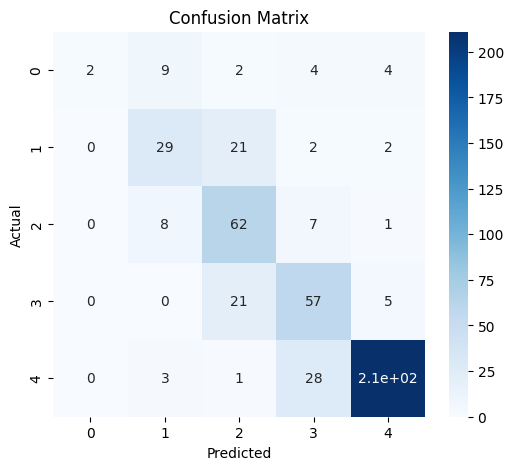

In [28]:
#This code generates a confusion matrix to summarize correct and incorrect predictions made by the classification model.

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

**Code 16: Calculating Model Performance Metrics**

In [31]:
#This code calculates various classification performance metrics, including Accuracy, Kappa, Precision, Recall, F1 Score, ROC-AUC, and MCC.

accuracy = accuracy_score(y_test, y_pred)
kappa = cohen_kappa_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)
mcc = matthews_corrcoef(y_test, y_pred)

results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Kappa",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC",
        "MCC"
    ],

    "Value": [
        accuracy,
        kappa,
        precision,
        recall,
        f1,
        auc,
        mcc
    ]
})

print(results)

      Metric     Value
0   Accuracy  0.753653
1      Kappa  0.637874
2  Precision  0.785709
3     Recall  0.753653
4   F1 Score  0.748796
5    ROC-AUC  0.927389
6        MCC  0.641697


**Code 17: Calculating ROC Curve Values**

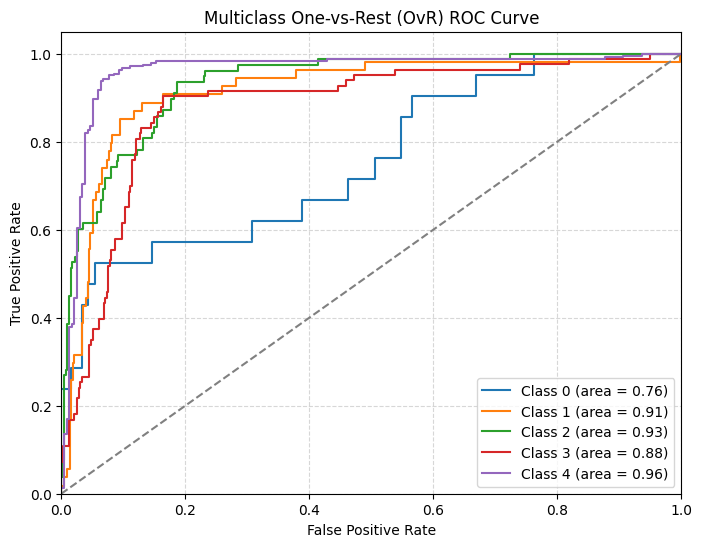

In [35]:
from sklearn.preprocessing import label_binarize

# Binarize the multi-class labels for plotting
n_classes = len(np.unique(y_test))
y_test_binarized = label_binarize(y_test, classes=np.unique(y_test))

plt.figure(figsize=(8, 6))

# Compute and plot ROC curve and ROC area for each individual class
for i in range(n_classes):
    fpr, tpr, _ = roc_curve(y_test_binarized[:, i], y_prob_all[:, i])
    roc_auc = roc_auc_score(y_test_binarized[:, i], y_prob_all[:, i])
    plt.plot(fpr, tpr, label=f"Class {i} (area = {roc_auc:.2f})")

plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multiclass One-vs-Rest (OvR) ROC Curve")
plt.legend(loc="lower right")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()